# Version 2
## Bahrain Rental Price Prediction
**Adam Ameer Isa Ali**

This is **Version 2 of the three-version assignment**. It follows the **final regression example** in the supplied `Intro to Deep Learning(2).ipynb` (cells 55–56), including its model code and hyperparameters. It is separate from Version 1 (the AI-designed approach). Version 3 (research-informed improvements) is not included here.

**Exact model settings:** Sequential; Dense layers 30 → 20 → 15 with ReLU; one linear output; Adam learning rate 0.01; MSE loss; up to 100 epochs; batch size 64; EarlyStopping on val_loss with patience 5 and restore_best_weights=True. The two train_test_split calls use the same 0.2 / 0.25 fractions and random_state=42 as the notes. StandardScaler is fitted only on X_train.

**Necessary dataset adaptations:** replace housing.csv with property_data.csv and median_house_value with rent; convert the Bahrain room/area text into three numeric inputs; drop incomplete selected training rows. Like the lecture’s exclusion of ocean_proximity, categorical fields are excluded. No embeddings, target clipping, tuning, ensembles, or additional model architecture are used.

The lecture is a teaching sequence with several intermediate demonstrations. This notebook implements its **final regression workflow**, not every intermediate training experiment. The classification notebook supplies the familiar prediction/evaluation layout, but classification outputs and accuracy do not apply to rent regression.

Run from top to bottom with `property_data.csv` beside the notebook or in `data/`. The optional final section also needs `test.csv`. If needed, install `tensorflow pandas numpy scikit-learn matplotlib seaborn` in your Python environment before starting. All imports are in the first code cell.

## 1. Import Libraries
Use the same Keras classes as the doctor’s regression example. The additional imports only load the files, convert text fields, and calculate regression metrics.

In [21]:
import re
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from keras.models import Sequential
from keras.layers import Dense, Input
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping
from IPython.display import display

## 2. Load Dataset
The lecture loads housing.csv. For this project, load the Bahrain rental dataset instead. The data directory selection is only a convenience for locating the file.

In [22]:
DATA_DIR = Path("data") if Path("data/property_data.csv").exists() else Path(".")
df = pd.read_csv(DATA_DIR / "property_data.csv")
display(df.head())

,Unnamed: 0,Property_id,property_type,offer,governorate,bedrooms,bathrooms,rent,location,city,...,is_super_agent,broker_id,floor_plans,is_featured,is_premium,description,is_verified,is_verified.1,is_exclusive,is_exclusive.1
0,27387,7343b863-a2cb-4d85-b2dd-935ea61365ff,Apartment,Residential for Rent,"Capital Governorate, Manama",studio,1,245.0,NaN,NaN,...,True,1031.0,NaN,False,False,A different furnished studio opportunity in Sa...,False,False,False,False
1,18554,f1a36ab5-1601-4127-a7a7-5095f167acca,Apartment,Rent,Capital Governorate,1,1,300.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,9295,bf629ae9-a3b2-4c2e-8e0e-b0ffce916fa7,Compound,Rent,Northern Governorate,5,5,1200.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,28118,26707746-825c-4d65-b63c-dfaa69421365,Apartment,Residential for Rent,Capital Governorate,3,3,600.0,NaN,NaN,...,False,15.0,NaN,True,False,Spacious 3 Bedroom Apartment for Rent in Seef ...,False,False,False,False
4,689,dbc18ce8-1481-480c-9b66-a42653038408,Apartment,for rent,Muharraq Governorate,1,2,450.0,Al Marsa Floating City,Amwaj Islands,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Basic EDA
### 3.1 Get a General Glimpse of the Data
Inspect data types and non-missing counts, as in the lecture.

In [23]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 32090 entries, 0 to 32089
Data columns (total 41 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         32090 non-null  int64  
 1   Property_id        32090 non-null  str    
 2   property_type      32090 non-null  str    
 3   offer              32090 non-null  str    
 4   governorate        32090 non-null  str    
 5   bedrooms           32078 non-null  str    
 6   bathrooms          32086 non-null  str    
 7   rent               32090 non-null  float64
 8   location           2899 non-null   str    
 9   city               8206 non-null   str    
 10  area_sqm           32090 non-null  str    
 11  listing_date       22564 non-null  str    
 12  Property_id.1      32090 non-null  str    
 13  URL                23884 non-null  str    
 14  include_w_e        23884 non-null  str    
 15  title              23884 non-null  str    
 16  area               23884 non-null

### 3.2 Check Missing Values
Display the percentage missing in each column.

In [24]:
display(df.isnull().mean().sort_values(ascending=False) * 100)

price_per_sqm        100.000000
completion_status    100.000000
floor_plans          100.000000
down_payment         100.000000
payment_methods       99.320661
plot_size_sqm         92.327828
location              90.966033
city                  74.428171
availability_date     71.748208
agency                70.314740
furnished             55.300717
is_premium            55.257089
description           55.257089
is_verified           55.257089
is_verified.1         55.257089
is_exclusive          55.257089
is_exclusive.1        55.257089
broker_id             55.257089
is_featured           55.257089
latitude              55.257089
longitude             55.257089
location_full         55.257089
is_super_agent        55.257089
agent_id              55.257089
period                55.257089
listing_date          29.685260
amenities             26.565908
include_w_e           25.571829
URL                   25.571829
title                 25.571829
area                  25.571829
bedrooms

### 3.3 Plot a Feature
Use a histogram of the bedroom count once it has been converted below. First we prepare the numeric columns required by the lecture’s numeric-input model.

## 4. Prepare the Bahrain Numerical Inputs
This preparation is specific to the Bahrain file, not a change to the network. Studios become zero bedrooms. Extract numerical room counts. Prefer sqm in mixed-unit area strings and convert sqft-only areas to sqm. Unparseable values become missing. The target remains the original rent in BHD.

In [25]:
def parse_rooms(value):
    if pd.isna(value):
        return np.nan
    text = str(value).lower()
    if "studio" in text:
        return 0.0
    match = re.search(r"\d+", text)
    return float(match.group()) if match else np.nan

def parse_area(value):
    if pd.isna(value):
        return np.nan
    text = str(value).replace(",", "").lower().strip()
    match = re.search(r"(\d+(?:\.\d+)?)\s*sqm", text)
    if match:
        result = float(match.group(1))
    else:
        match = re.search(r"(\d+(?:\.\d+)?)\s*sqft", text)
        if match:
            result = float(match.group(1)) * 0.09290304
        else:
            try:
                result = float(text)
            except ValueError:
                return np.nan
    return result if np.isfinite(result) and result > 0 else np.nan

df["bedrooms_num"] = df["bedrooms"].apply(parse_rooms)
df["bathrooms_num"] = df["bathrooms"].apply(parse_rooms)
df["area_sqm_num"] = df["area_sqm"].apply(parse_area)
df["rent"] = pd.to_numeric(df["rent"], errors="coerce")
display(df[["bedrooms_num", "bathrooms_num", "area_sqm_num", "rent"]].head())

,bedrooms_num,bathrooms_num,area_sqm_num,rent
0,0.0,1.0,43.0,245.0
1,1.0,1.0,65.0,300.0
2,5.0,5.0,400.0,1200.0
3,3.0,3.0,160.0,600.0
4,1.0,2.0,80.0,450.0


### Plot Bedrooms
Follow the lecture’s seaborn histogram example using the rental dataset’s numerical bedroom feature.

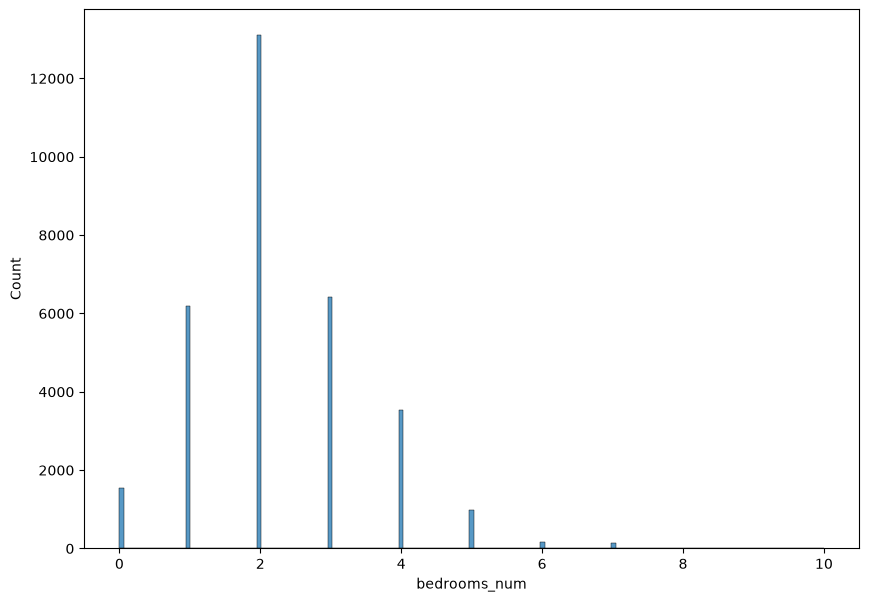

In [26]:
plt.figure(figsize=(10, 7))
sns.histplot(data=df, x="bedrooms_num")
plt.show()

### Drop Missing Values
The lecture uses df.dropna(). Apply the same operation after selecting the three numerical predictors and rent, so missing values in unrelated listing columns do not remove otherwise usable observations. Report how many rows remain. This version’s evaluation covers complete selected rows only.

In [27]:
features = ["bedrooms_num", "bathrooms_num", "area_sqm_num"]
original_rows = len(df)
df = df[features + ["rent"]].replace([np.inf, -np.inf], np.nan)
df = df.dropna()
print("Original rows:", original_rows)
print("Complete rows:", len(df))
print("Dropped rows:", original_rows - len(df))
print("Shape:", df.shape)

Original rows: 32090
Complete rows: 32075
Dropped rows: 15
Shape: (32075, 4)


## 5. Understanding Data Splitting for Neural Networks
Use the exact split procedure from the notes: 20% labeled test, then 25% of the remaining 80% for validation. This gives approximately 60% training, 20% validation, and 20% labeled test.

The labeled test here is a subset of the training CSV; it is different from the competition’s unlabeled test.csv. These are ordinary random row splits, matching the notes. Repeated listings may cross splits, so this is not a group-independent evaluation.

In [28]:
# Select features and target
X = df.drop(columns=["rent"])
y = df["rent"]

# Split data into train, val and test sets
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.25, random_state=42)

### Check the Shapes
Check the three subsets before fitting a model.

In [29]:
print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Labeled test:", X_test.shape)

Train: (19245, 3)
Validation: (6415, 3)
Labeled test: (6415, 3)


## 6. Data Scaling
Copy the lecture’s final scaling procedure: fit StandardScaler on X_train only, then transform validation and test features. The target is not scaled or clipped.

In [30]:
# Scale your data before fitting your model


# Initialize the scaler
scaler = StandardScaler()

# Fit only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform validation and test data
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

## 7. Your Neural Network Model — The Final Version from the Notes
The following code is copied from the doctor’s final regression model cell.

**Step 1 — Architecture:** input width from X.shape[1], hidden layers 30 → 20 → 15 with ReLU, and one linear output.

**Step 2 — Compilation:** Adam(learning_rate=0.01) and loss='mse', exactly as in the notes. MSE is the training loss; MAE will be calculated separately for the competition.

**Step 3 — Fitting:** validation data, up to 100 epochs, batches of 64, and EarlyStopping with patience 5 and restored best weights. One epoch means a complete pass through the training examples.

The original comments are preserved in the code below. Where a comment says “1 feature” or “3 neurons”, the actual code is authoritative: the input has three selected features and the first hidden layer has 30 neurons. The notes do not set a neural-network seed, so fitted weights and results may vary between runs even though the row splits are fixed.

In [31]:
#The final version


#Step 1

model = Sequential()

model.add(Input(shape=(X.shape[1],)))  #input layer with 1 feature
model.add(Dense(30, activation = "relu"))  # hidden layer with 3 neurons (nodes)
model.add(Dense(20, activation = "relu"))  # hidden layer with 20 neurons
model.add(Dense(15, activation = "relu"))  # hidden layer with 15 neurons
model.add(Dense(1, activation = "linear"))  # output layer

#Step 2: Instantiate a custom optimizer

optimizer = Adam(learning_rate=0.01)  # Default Adam LR = 0.001

model.compile(
            loss='mse', 
            optimizer=optimizer)

#Step 3: Fitting with early stopping

es=EarlyStopping(monitor='val_loss', 
                 patience=5,
                 restore_best_weights=True)

history = model.fit(
                    X_train_scaled,
                    y_train, 
                    validation_data=(X_val_scaled, y_val),
                    epochs=100,
                    batch_size=64,
                    callbacks=[es])

Epoch 1/100
301/301 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 58791060.0000 - val_loss: 32374324.0000
Epoch 2/100
301/301 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 58719752.0000 - val_loss: 32372584.0000
Epoch 3/100
301/301 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 58712996.0000 - val_loss: 32377908.0000
Epoch 4/100
301/301 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 58712840.0000 - val_loss: 32414274.0000
Epoch 5/100
301/301 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 58714276.0000 - val_loss: 32362088.0000
Epoch 6/100
301/301 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 58716924.0000 - val_loss: 32389922.0000
Epoch 7/100
301/301 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 58714036.0000 - val_loss: 32358456.0000
Epoch 8/100
301/301 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 58719492.0000 - val_loss: 32384992.0000
Epoch 9/100
301/301 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 58711152.0000 - val_loss: 32402084.0000
Epoch 10/100
301/301 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 58726904.0000 - val_loss: 323

### Model Summary
Display the architecture and trainable parameter count as in the notes.

In [32]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 30)             │           120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 20)             │           620 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 15)             │           315 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            16 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,215 (12.56 KB)

 Trainable params: 1,071 (4.18 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,144 (8.38 KB)

## 8. History
Convert history.history into a DataFrame, matching the lecture. Loss and val_loss are MSE values, measured in squared BHD; they are not MAE.

In [33]:
history_df = pd.DataFrame(history.history)
display(history_df.head())

,loss,val_loss
0,58791060.0,32374324.0
1,58719752.0,32372584.0
2,58712996.0,32377908.0
3,58712840.0,32414274.0
4,58714276.0,32362088.0


### Plot Training and Validation Loss
Use the same plotting pattern as the lecture to compare learning curves.

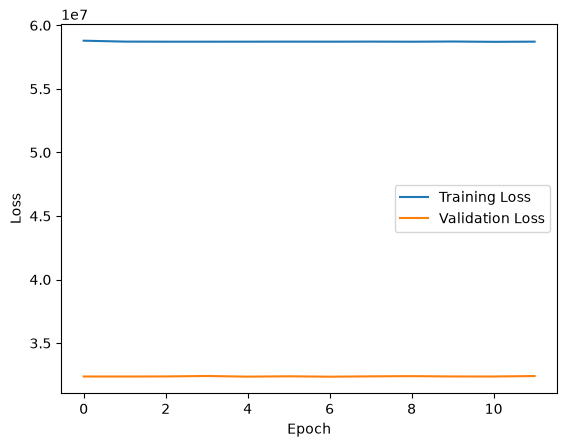

In [34]:
plt.plot(history_df['loss'], label='Training Loss')
plt.plot(history_df['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

## 9. Prediction
### Predict One Observation
Keep the batch dimension using [:1], following the prediction pattern in the classification notes. Because this is regression, the output is a numerical rent; do not use argmax.

In [35]:
single_pred = model.predict(X_test_scaled[:1])
print("Predicted rent:", single_pred[0, 0])
print("Actual rent:", y_test.iloc[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step
Predicted rent: 742.5598
Actual rent: 550.0


### Predict the Labeled Test Set
Generate one prediction for each held-out observation. Use raw model predictions for the evaluation, without clipping or rounding.

In [36]:
y_pred = model.predict(X_test_scaled)
y_pred = y_pred.ravel()

201/201 ━━━━━━━━━━━━━━━━━━━━ 0s 704us/step


## 10. Evaluating the Model
model.evaluate reports MSE because that is the compiled loss. Calculate MAE separately to express average absolute prediction error in BHD. RMSE and R² are additional descriptive metrics. Classification accuracy, recall, and confusion matrices do not apply here.

In [37]:
print("Model test loss (MSE):", model.evaluate(X_test_scaled, y_test))
print("Test MAE (BHD):", mean_absolute_error(y_test, y_pred))
print("Test RMSE (BHD):", np.sqrt(mean_squared_error(y_test, y_pred)))
print("Test R²:", r2_score(y_test, y_pred))

201/201 ━━━━━━━━━━━━━━━━━━━━ 0s 942us/step - loss: 7211788.0000
Model test loss (MSE): 7211788.0
Test MAE (BHD): 292.5906757452854
Test RMSE (BHD): 2685.4775181044747
Test R²: 0.012116020493273538


### Error Analysis
Compare actual and predicted rent, then inspect the largest absolute errors. Extreme original rents can have a large effect on MSE training and evaluation. Do not change the target or tune the network in this notes-only version.

In [38]:
results = pd.DataFrame({"Actual Rent": y_test.to_numpy(), "Predicted Rent": y_pred})
results["Absolute Error"] = np.abs(results["Actual Rent"] - results["Predicted Rent"])
display(results.head(10))
display(results.nlargest(10, "Absolute Error"))

,Actual Rent,Predicted Rent,Absolute Error
0,550.0,742.559814,192.559814
1,280.0,337.850861,57.850861
2,500.0,1031.470581,531.470581
3,300.0,321.047119,21.047119
4,1000.0,1042.514526,42.514526
5,1200.0,1563.499146,363.499146
6,650.0,772.189636,122.189636
7,350.0,369.894745,19.894745
8,425.0,366.716156,58.283844
9,300.0,269.217163,30.782837


,Actual Rent,Predicted Rent,Absolute Error
3932,127000.0,337.850861,126662.149139
2417,126000.0,1436.774902,124563.225098
4096,68000.0,369.629852,67630.370148
4455,58000.0,368.305450,57631.694550
2442,52000.0,270.931976,51729.068024
3138,40000.0,367.245911,39632.754089
3025,36400.0,335.018982,36064.981018
2449,16000.0,570.367432,15429.632568
2281,18000.0,4542.607910,13457.392090
3803,17000.0,4320.664551,12679.335449


## 11. Optional Competition Submission — Dataset-Specific Addition
This section is outside the doctor’s teaching example and does not change or refit the network. It applies the already-trained model to test.csv.

Unlike labeled training rows, competition rows cannot be dropped because every ID needs a prediction. Therefore, if a selected competition input is missing, fill it with the corresponding **training-split median** before applying the existing scaler. Report the number of affected rows. This submission-only fallback is explicitly an addition to the lecture, not a claim that the notes use imputation.

Use the current test file’s IDs and order. Save raw predictions with the requested Property_id,Rent header; no ensemble, target clipping, prediction clipping, or full-data refit is introduced. The competition score remains unknown until submission.

In [39]:
test_path = DATA_DIR / "test.csv"
if test_path.exists():
    competition_test = pd.read_csv(test_path, dtype={"Property_id": "string"})
    competition_test["bedrooms_num"] = competition_test["bedrooms"].apply(parse_rooms)
    competition_test["bathrooms_num"] = competition_test["bathrooms"].apply(parse_rooms)
    competition_test["area_sqm_num"] = competition_test["area_sqm"].apply(parse_area)
    X_competition = competition_test[features].replace([np.inf, -np.inf], np.nan)
    print("Competition rows requiring the missing-input fallback:", X_competition.isna().any(axis=1).sum())
    X_competition = X_competition.fillna(X_train.median())
    assert X_competition.notna().all().all()
    X_competition_scaled = scaler.transform(X_competition)
    competition_pred = model.predict(X_competition_scaled).ravel()
    submission = pd.DataFrame({"Property_id": competition_test["Property_id"], "Rent": competition_pred})
    assert len(submission) == len(competition_test)
    assert submission["Property_id"].is_unique and submission["Property_id"].notna().all()
    assert np.isfinite(submission["Rent"]).all()
    print("Negative predictions:", int((submission["Rent"] < 0).sum()))
    output_dir = Path("version1")
    output_dir.mkdir(exist_ok=True)
    submission.to_csv(output_dir / "submission_version1.csv", index=False)
    display(submission.head())
    print("Saved rows:", len(submission))
else:
    print("No test.csv found. The lecture-model evaluation above is complete; submission is skipped.")

Competition rows requiring the missing-input fallback: 3
112/112 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Negative predictions: 0


,Property_id,Rent
0,25c91c33-a523-42f2-8c10-9f340005471d,658.193848
1,6bcb7804-9cd7-4792-8cbe-abb4de65058a,676.296814
2,7b733e67-ec21-4427-95f8-4be3d9d18f6b,1228.613281
3,feefd51f-a7d6-45b0-a9eb-200d9f9821b4,345.239197
4,cca286dd-ddc6-41c2-9584-f8e17461220f,652.671936


Saved rows: 3566


## 12. Match to the Doctor’s Final Example

| Item | Doctor’s notes | Version 2 |
|---|---|---|
| Split function | train_test_split | Same |
| Test and validation fractions | 0.2, then 0.25 | Same |
| Both split seeds | random_state=42 | Same |
| Scaling | StandardScaler, fit on X_train | Same |
| Network | Sequential, model.add | Same |
| Hidden layers | 30 → 20 → 15, ReLU | Same |
| Output | Dense(1, activation='linear') | Same |
| Optimizer | Adam(learning_rate=0.01) | Same |
| Training loss | mse | Same |
| Epoch limit and batch size | 100 and 64 | Same |
| Early stopping | val_loss, patience=5, restore_best_weights=True | Same |

**Dataset-only changes:** Bahrain CSV and target names; numerical room/area conversion; selection of three numeric predictors; complete-case training; MAE reporting; optional submission formatting and test-input median fallback. The final model cell itself is copied from the uploaded notes.

**Authorship note:** prepared with AI assistance to implement the supplied lecture method. This is the notes-method version, not a claim that it was written without AI assistance.